<a href="https://colab.research.google.com/github/AuroraEspadas/PICASSO/blob/main/particle_detection_counting_and_intensity_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

# Parameters






In [ ]:
BLUE_PATH = "/content/Snap-27_AF350_ORG.tif"
GREEN_PATH = "/content/Snap-27_AF488_ORG.tif"
RED_PATH = "/content/Snap-27_Cy5_ORG.tif"

SIGMA = 2
MIN_DISTANCE = 6
THRESHOLD_ABS = 2
MASK_THRESHOLD = 1

IMAGELOADING; GRAY

In [ ]:
def load_image(path):

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(
            f"Could not load image: {path}"
        )

    return img


# Load channels

In [ ]:
blue = load_image(BLUE_PATH)
green = load_image(GREEN_PATH)
red = load_image(RED_PATH)

images = {
    "Blue": blue,
    "Green": green,
    "Red": red
}

if len({img.shape for img in images.values()}) != 1:
    raise ValueError(
        "Images have different dimensions."
    )


SMOOTHING

In [ ]:
blue_smooth = gaussian_filter(
    blue.astype(np.float32),
    sigma=SIGMA
)

PEAK DETECTION

In [ ]:

peaks = peak_local_max(
    blue_smooth,
    min_distance=MIN_DISTANCE,
    threshold_abs=THRESHOLD_ABS,
    exclude_border=False
)

print(f"Detected peaks: {len(peaks)}")

Detected peaks: 37


MASK

In [ ]:
foreground = blue_smooth >= MASK_THRESHOLD

MARKERS

In [ ]:

markers = np.zeros_like(
    blue,
    dtype=np.int32
)

for i, (y, x) in enumerate(peaks, start=1):

    if foreground[y, x]:
        markers[y, x] = i


WASHED

In [ ]:

labels = watershed(
    -blue_smooth,
    markers=markers,
    mask=foreground
)

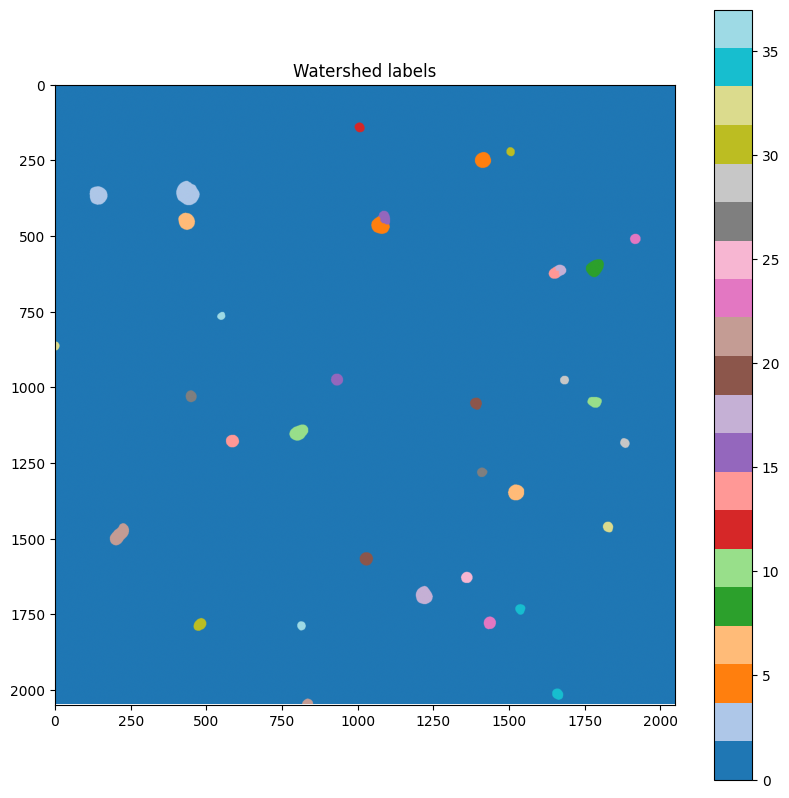

In [ ]:
plt.figure(figsize=(10,10))
plt.imshow(labels, cmap="tab20")
plt.colorbar()
plt.title("Watershed labels")
plt.show()

GLOBAL BG

In [ ]:
background_mask = labels == 0

blue_bg = np.median(
    blue[background_mask]
)

green_bg = np.median(
    green[background_mask]
)

red_bg = np.median(
    red[background_mask]
)

print("\nBackground values")
print(f"Blue : {blue_bg:.2f}")
print(f"Green: {green_bg:.2f}")
print(f"Red  : {red_bg:.2f}")


Background values
Blue : 0.00
Green: 0.00
Red  : 0.00


PARTICLE QUANTIFICATION

In [ ]:
results = []

overlay = cv2.cvtColor(
    blue,
    cv2.COLOR_GRAY2RGB
)

for particle_id, (y, x) in enumerate(peaks, start=1):

    particle_mask = labels == particle_id

    area = np.sum(particle_mask)

    if area == 0:
        continue

    blue_vals = np.clip(
        blue[particle_mask].astype(float) - blue_bg,
        0,
        None
    )

    green_vals = np.clip(
        green[particle_mask].astype(float) - green_bg,
        0,
        None
    )

    red_vals = np.clip(
        red[particle_mask].astype(float) - red_bg,
        0,
        None
    )

    results.append({

        "Particle_ID": particle_id,
        "X_pixel": int(x),
        "Y_pixel": int(y),
        "Area_pixels": int(area),

        "Blue_mean": blue_vals.mean(),
        "Blue_SD": blue_vals.std(),

        "Green_mean": green_vals.mean(),
        "Green_SD": green_vals.std(),

        "Red_mean": red_vals.mean(),
        "Red_SD": red_vals.std()

    })

    particle_uint8 = (
        particle_mask.astype(np.uint8) * 255
    )

    contours, _ = cv2.findContours(
        particle_uint8,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        overlay,
        contours,
        -1,
        (255, 0, 0),
        1
    )


In [ ]:
DATAFRAME

In [ ]:

df = pd.DataFrame(results)

print(f"\nParticles quantified: {len(df)}")

display(df)


Particles quantified: 37


,Particle_ID,X_pixel,Y_pixel,Area_pixels,Blue_mean,Blue_SD,Green_mean,Green_SD,Red_mean,Red_SD
0,1,1198,652,2126,5.189558,4.271292,0.880056,1.037494,3.194732,3.269732
1,2,144,367,2854,4.844429,3.094682,1.400140,1.432313,1.782411,1.279436
2,3,451,366,4559,4.786576,2.863010,1.558675,1.408000,1.668129,0.714418
3,4,1413,249,2166,5.173130,3.290216,0.828255,0.863786,0.680517,0.475104
4,5,1065,467,2200,4.071818,2.288176,0.900909,0.904634,1.270455,0.750176
5,6,1521,1350,2190,4.267123,2.691500,0.573516,0.681009,1.210046,0.646515
6,7,434,458,2386,4.138307,2.499150,2.145851,1.777106,2.562028,1.053736
7,8,1787,598,1122,5.034759,2.667164,1.057041,0.914505,26.820856,13.674696
8,9,1776,614,1429,4.168649,2.437225,0.863541,0.924887,19.906928,13.045075
9,10,1782,1051,1319,3.362396,2.197382,0.714177,0.748638,3.410917,2.272438


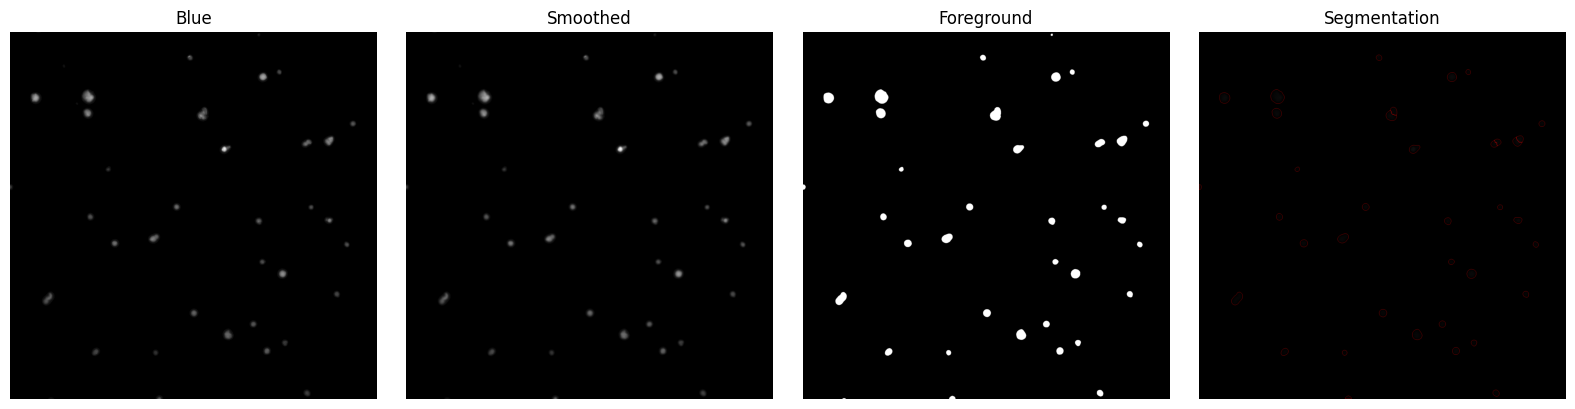

In [ ]:

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16,4)
)

axes[0].imshow(
    blue,
    cmap="gray"
)
axes[0].set_title("Blue")

axes[1].imshow(
    blue_smooth,
    cmap="gray"
)
axes[1].set_title("Smoothed")

axes[2].imshow(
    foreground,
    cmap="gray"
)
axes[2].set_title("Foreground")

axes[3].imshow(
    overlay
)
axes[3].set_title("Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
all_particles_mask = labels > 0

print("Mean intensity in all AF350 particles:")
print(
    "AF350:",
    blue[all_particles_mask].mean()
)

print(
    "AF488:",
    green[all_particles_mask].mean()
)

print(
    "Cy5:",
    red[all_particles_mask].mean()
)

Mean intensity in all AF350 particles:
AF350: 3.695583388266315
AF488: 0.982201713909031
Cy5: 2.8098126000565027


In [ ]:
all_particles_mask = labels > 0

blue_corrected = np.clip(
    blue[all_particles_mask].astype(float) - blue_bg,
    0,
    None
)

green_corrected = np.clip(
    green[all_particles_mask].astype(float) - green_bg,
    0,
    None
)

red_corrected = np.clip(
    red[all_particles_mask].astype(float) - red_bg,
    0,
    None
)

print("Background-corrected means ± SD")
print(
    f"AF350: {blue_corrected.mean():.3f} ± {blue_corrected.std():.3f}"
)
print(
    f"AF488: {green_corrected.mean():.3f} ± {green_corrected.std():.3f}"
)
print(
    f"Cy5: {red_corrected.mean():.3f} ± {red_corrected.std():.3f}"
)

Background-corrected means ± SD
AF350: 3.696 ± 2.442
AF488: 0.982 ± 1.121
Cy5: 2.810 ± 5.996


In [ ]:
print(df["Area_pixels"].describe())

count      37.000000
mean     1435.000000
std       866.735286
min       352.000000
25%       879.000000
50%      1197.000000
75%      2126.000000
max      4559.000000
Name: Area_pixels, dtype: float64


NORMALIZATION

In [ ]:
blue_ref = df["Blue_mean"].mean()

green_norm = df["Green_mean"] / blue_ref
blue_norm = df["Blue_mean"] / blue_ref
red_norm = df["Red_mean"] / blue_ref

print("\nNormalized to AF350 (Blue)")

print(
    f'("1:1 Albumin Fibrinogen", "Green", '
    f'{green_norm.mean():.4f}, {green_norm.sem():.4f}),'
)

print(
    f'("1:1 Albumin Fibrinogen", "Blue", '
    f'{blue_norm.mean():.4f}, {blue_norm.sem():.4f}),'
)

print(
    f'("1:1 Albumin Fibrinogen", "Red", '
    f'{red_norm.mean():.4f}, {red_norm.sem():.4f}),'
)



Normalized to AF350 (Blue)
("1:1 Albumin Fibrinogen", "Green", 0.2764, 0.0213),
("1:1 Albumin Fibrinogen", "Blue", 1.0000, 0.0432),
("1:1 Albumin Fibrinogen", "Red", 0.9940, 0.2805),


Data from the image of AlbFibri Snap27


```
# Normalized to AF350 (Blue)
("1:1 Albumin Fibrinogen", "Green", 0.2764, 0.0213),
("1:1 Albumin Fibrinogen", "Blue", 1.0000, 0.0432),
("1:1 Albumin Fibrinogen", "Red", 0.9940, 0.2805),
```



